##Pre Processing

In [51]:
#import libraries
!pip install ucimlrepo
!pip install pandas
!pip install matplotlib
!pip install seaborn
!pip install statsmodels
!pip install scikit-learn
!pip install numpy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
raisin = fetch_ucirepo(id=850)

# Features & Target
X = raisin.data.features.copy()

y = raisin.data.targets.squeeze().copy()

df = X.copy()
df["Class"] = y



In [53]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [54]:
df.shape

(900, 8)

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   ConvexArea       900 non-null    int64  
 5   Extent           900 non-null    float64
 6   Perimeter        900 non-null    float64
 7   Class            900 non-null    object 
dtypes: float64(5), int64(2), object(1)
memory usage: 56.4+ KB


In [56]:
df.isnull().sum()

,0
Area,0
MajorAxisLength,0
MinorAxisLength,0
Eccentricity,0
ConvexArea,0
Extent,0
Perimeter,0
Class,0


In [57]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


In [58]:
y.value_counts()

,count
Class,
Kecimen,450
Besni,450


In [59]:
y.value_counts(normalize=True)

,proportion
Class,
Kecimen,0.5
Besni,0.5


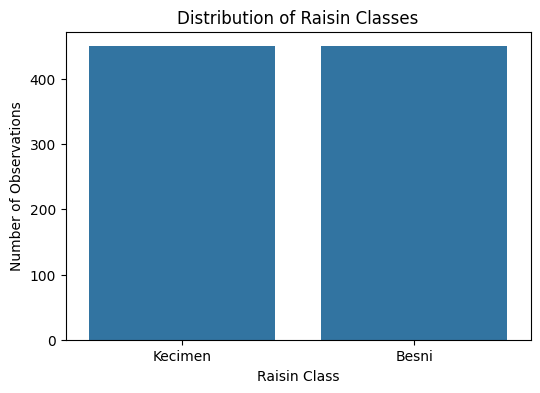

In [60]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Class")

plt.title("Distribution of Raisin Classes")
plt.xlabel("Raisin Class")
plt.ylabel("Number of Observations")

plt.show()

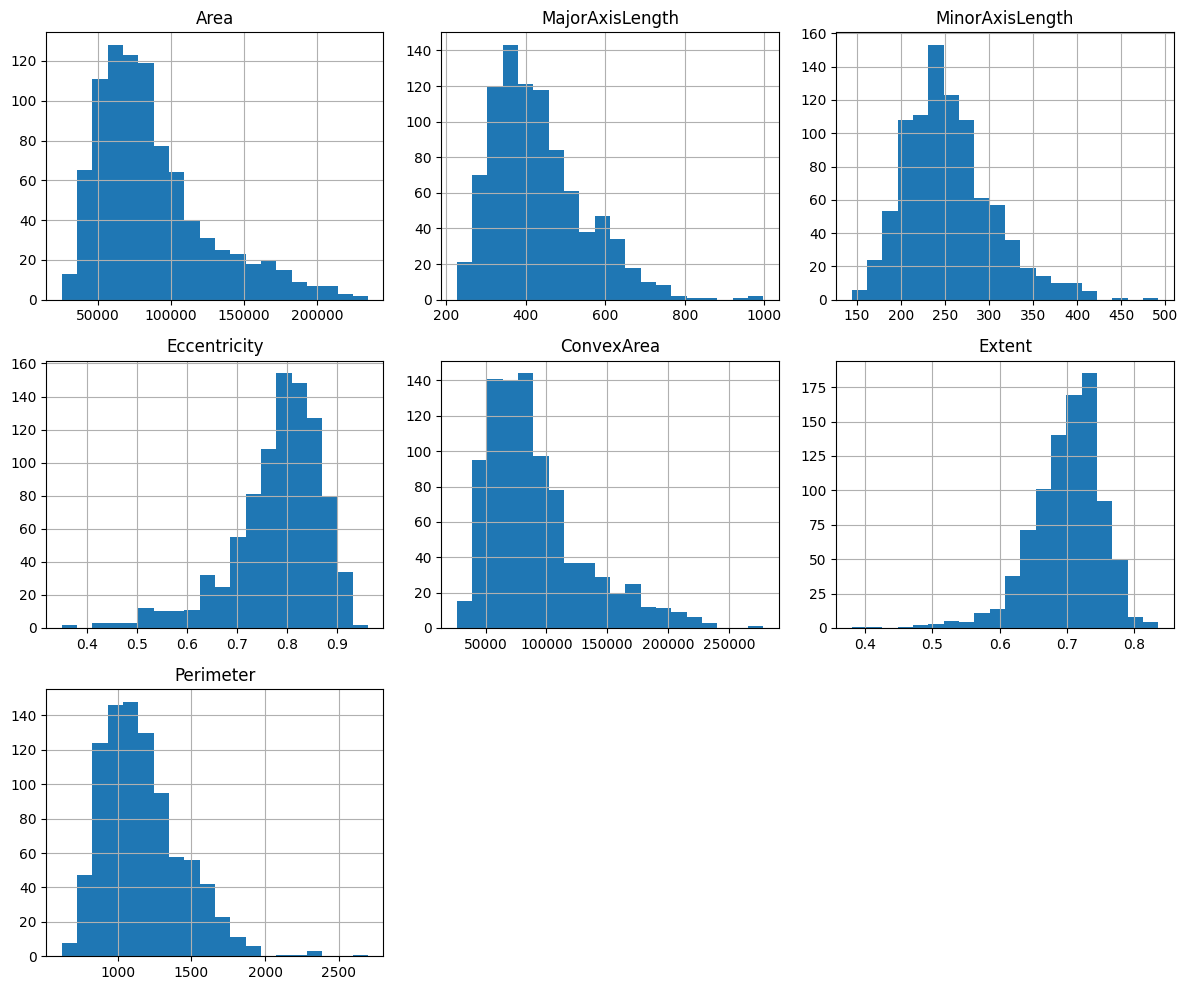

In [61]:
X.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

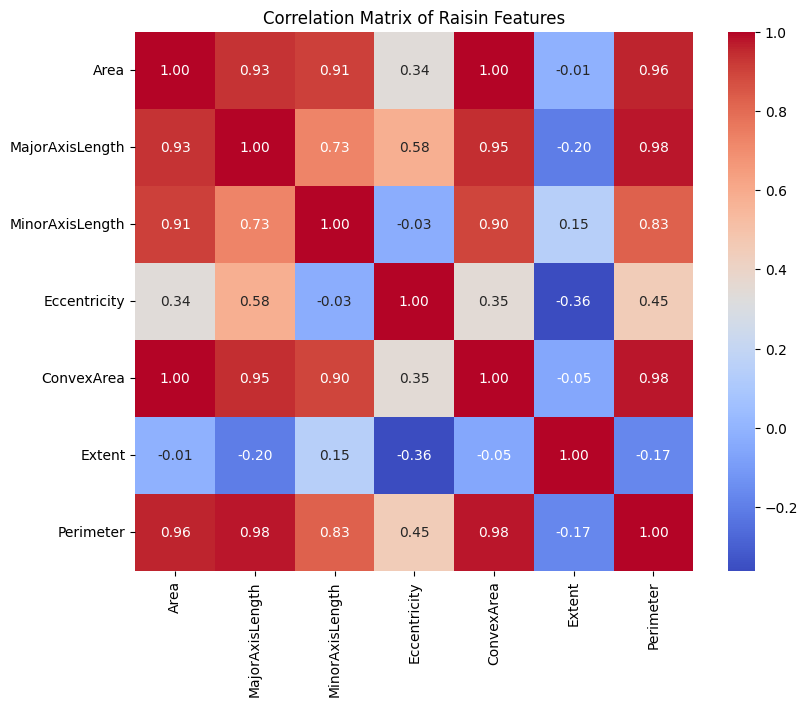

In [62]:
corr_matrix = X.corr()
plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm")

plt.title("Correlation Matrix of Raisin Features")
plt.show()

df["Class_encoded"] = df["Class"].map({
    "Kecimen": 0,
    "Besni": 1
})

In [63]:
df["Class_encoded"] = df["Class"].map({
    "Kecimen": 0,
    "Besni": 1
})

target_corr = df.corr(numeric_only=True)["Class_encoded"].sort_values(
    ascending=False
)

target_corr

,Class_encoded
Class_encoded,1.000000
MajorAxisLength,0.673194
Perimeter,0.665981
Area,0.625715
ConvexArea,0.625567
MinorAxisLength,0.503102
Eccentricity,0.438500
Extent,-0.154689


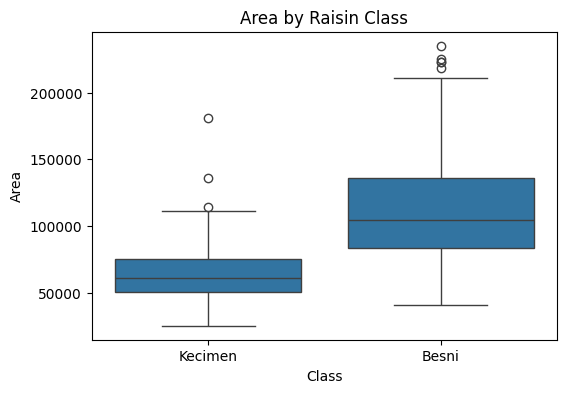

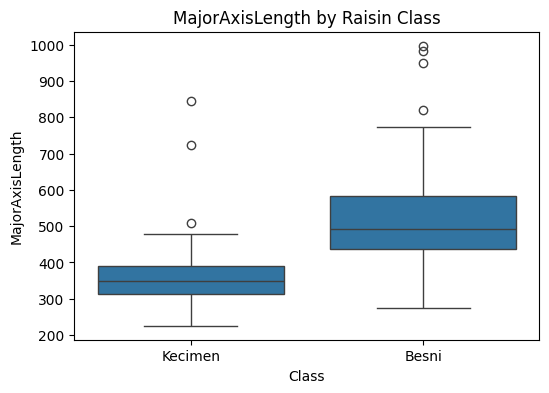

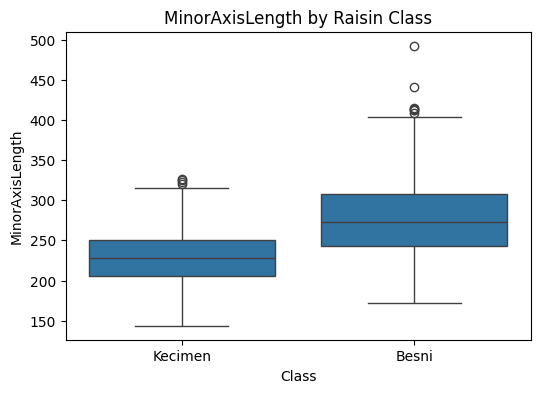

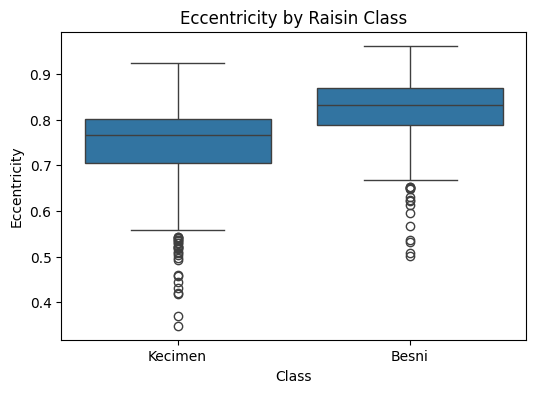

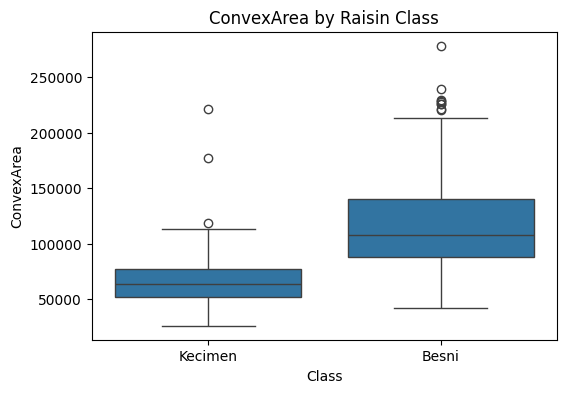

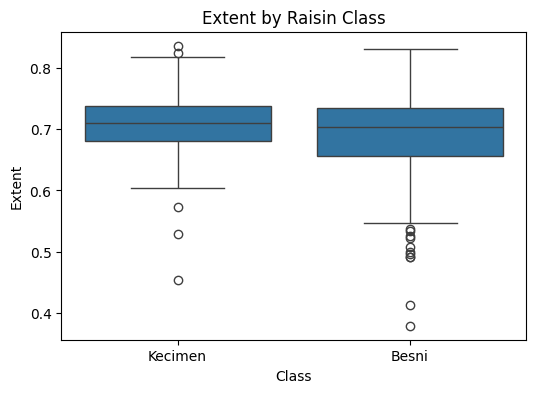

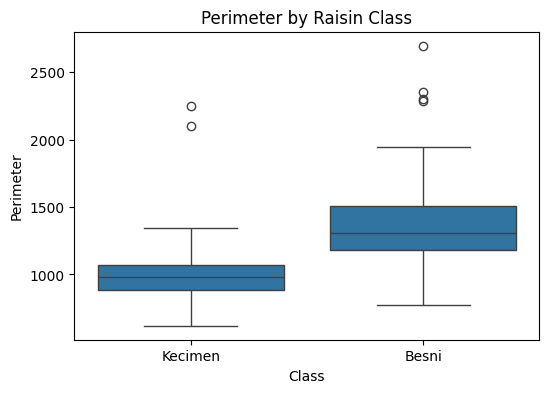

In [64]:
features = [
    "Area",
    "MajorAxisLength",
    "MinorAxisLength",
    "Eccentricity",
    "ConvexArea",
    "Extent",
    "Perimeter"
]

for feature in features:
    plt.figure(figsize=(6, 4))

    sns.boxplot(
        data=df,
        x="Class",
        y=feature
    )

    plt.title(f"{feature} by Raisin Class")
    plt.show()

In [65]:
from sklearn.model_selection import train_test_split

X_selected = X[
    ["Area", "MajorAxisLength", "MinorAxisLength", "Eccentricity"]
]

X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [66]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Standardization
standard_scaler = StandardScaler()

X_train_std = standard_scaler.fit_transform(X_train)
X_test_std = standard_scaler.transform(X_test)

# Normalization
minmax_scaler = MinMaxScaler()

X_train_norm = minmax_scaler.fit_transform(X_train)
X_test_norm = minmax_scaler.transform(X_test)

## Model Construction

### Decision Tree Classifier



In [67]:
from sklearn.tree import DecisionTreeClassifier

# Create baseline Decision Tree
dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train model
dt_model.fit(X_train, y_train)

# Predictions
y_train_pred_dt = dt_model.predict(X_train)
y_test_pred_dt = dt_model.predict(X_test)

In [68]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Training Accuracy:",accuracy_score(y_train, y_train_pred_dt))

print("Testing Accuracy:",accuracy_score(y_test, y_test_pred_dt))

print("Testing Precision:",precision_score(y_test,y_test_pred_dt,pos_label="Besni"))

print("Testing Recall:",recall_score(y_test,y_test_pred_dt,pos_label="Besni"))

print("Testing F1:",f1_score(y_test,y_test_pred_dt,pos_label="Besni"))

Training Accuracy: 1.0
Testing Accuracy: 0.7944444444444444
Testing Precision: 0.8192771084337349
Testing Recall: 0.7555555555555555
Testing F1: 0.7861271676300579


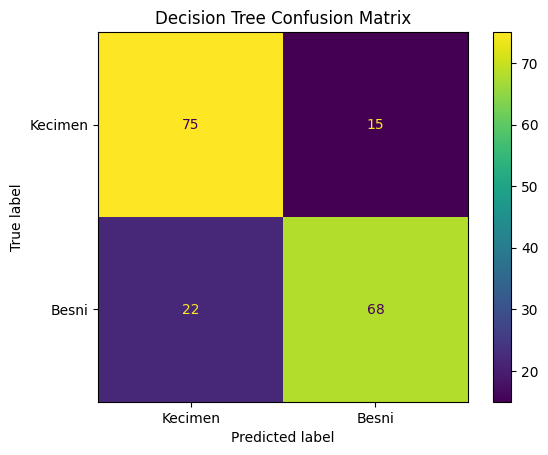

In [69]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_dt = confusion_matrix(y_test,y_test_pred_dt,labels=["Kecimen", "Besni"])

disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt,display_labels=["Kecimen", "Besni"])
disp.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [70]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_test_pred_dt))

              precision    recall  f1-score   support

       Besni       0.82      0.76      0.79        90
     Kecimen       0.77      0.83      0.80        90

    accuracy                           0.79       180
   macro avg       0.80      0.79      0.79       180
weighted avg       0.80      0.79      0.79       180



### GridSearchCV


In [71]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# Hyperparameters to test
param_grid = {
    "criterion": ["gini","entropy"],
    "max_depth": [2, 3, 4, 5, 6, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5, 10]}

#Base Decision Tree
dt_grid_model = DecisionTreeClassifier(random_state=42)

# Grid search with 5-fold cross-validation
grid_search_dt = GridSearchCV(estimator=dt_grid_model,
    param_grid=param_grid, cv=5, scoring="accuracy", n_jobs=-1)

grid_search_dt.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search_dt.best_params_)
print("\nBest Cross-Validation Accuracy:")
print(grid_search_dt.best_score_)

Best Parameters:
{'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 10, 'min_samples_split': 2}

Best Cross-Validation Accuracy:
0.8541666666666666


In [72]:
best_dt = grid_search_dt.best_estimator_

print(best_dt)

DecisionTreeClassifier(max_depth=2, min_samples_leaf=10, random_state=42)


In [73]:
# Predictions from tuned Decision Tree
y_train_pred_best_dt = best_dt.predict(X_train)
y_test_pred_best_dt = best_dt.predict(X_test)

print("Tuned Training Accuracy:",
      accuracy_score(y_train, y_train_pred_best_dt))

print("Tuned Testing Accuracy:",
      accuracy_score(y_test, y_test_pred_best_dt))

print("Tuned Testing Precision:",
      precision_score(
          y_test,
          y_test_pred_best_dt,
          pos_label="Besni"
      ))

print("Tuned Testing Recall:",
      recall_score(
          y_test,
          y_test_pred_best_dt,
          pos_label="Besni"
      ))

print("Tuned Testing F1:",
      f1_score(
          y_test,
          y_test_pred_best_dt,
          pos_label="Besni"
      ))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_best_dt
    )
)

Tuned Training Accuracy: 0.8611111111111112
Tuned Testing Accuracy: 0.8777777777777778
Tuned Testing Precision: 0.9358974358974359
Tuned Testing Recall: 0.8111111111111111
Tuned Testing F1: 0.8690476190476191

Classification Report:
              precision    recall  f1-score   support

       Besni       0.94      0.81      0.87        90
     Kecimen       0.83      0.94      0.89        90

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



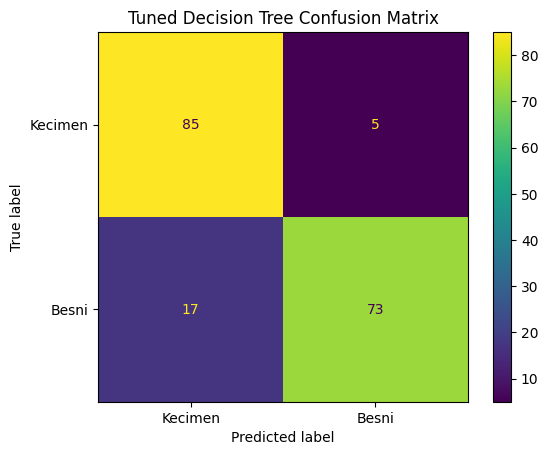

In [74]:
cm_best_dt = confusion_matrix(
    y_test,
    y_test_pred_best_dt,
    labels=["Kecimen", "Besni"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_dt,
    display_labels=["Kecimen", "Besni"]
)

disp.plot()
plt.title("Tuned Decision Tree Confusion Matrix")
plt.show()

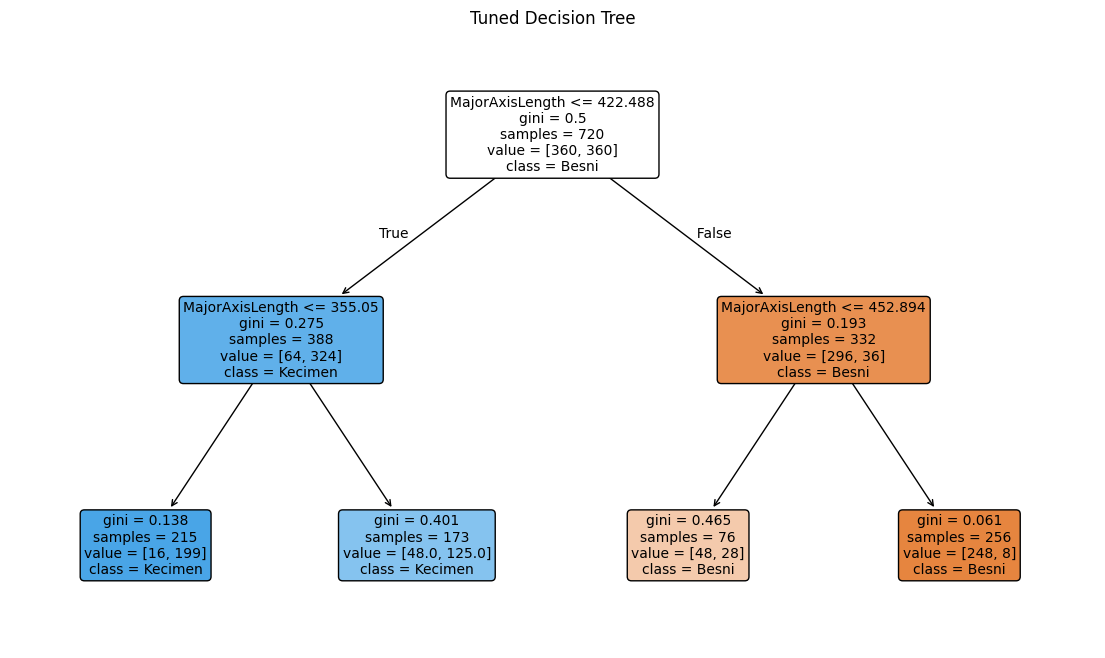

In [75]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

plot_tree(
    best_dt,
    feature_names=X_train.columns,
    class_names=best_dt.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Tuned Decision Tree")
plt.show()

### Random Forest

Essentially many trees operate and vote the best one

In [76]:
from sklearn.ensemble import RandomForestClassifier

# Baseline Random Forest
rf_model = RandomForestClassifier(
    random_state=42
)

rf_model.fit(X_train, y_train)

# Predictions
y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)

In [77]:
print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred_rf))

print("Testing Accuracy:",
      accuracy_score(y_test, y_test_pred_rf))

print("Testing Precision:",
      precision_score(
          y_test,
          y_test_pred_rf,
          pos_label="Besni"
      ))

print("Testing Recall:",
      recall_score(
          y_test,
          y_test_pred_rf,
          pos_label="Besni"
      ))

print("Testing F1:",
      f1_score(
          y_test,
          y_test_pred_rf,
          pos_label="Besni"
      ))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_rf
    )
)

Training Accuracy: 1.0
Testing Accuracy: 0.8388888888888889
Testing Precision: 0.9178082191780822
Testing Recall: 0.7444444444444445
Testing F1: 0.8220858895705522

Classification Report:
              precision    recall  f1-score   support

       Besni       0.92      0.74      0.82        90
     Kecimen       0.79      0.93      0.85        90

    accuracy                           0.84       180
   macro avg       0.85      0.84      0.84       180
weighted avg       0.85      0.84      0.84       180



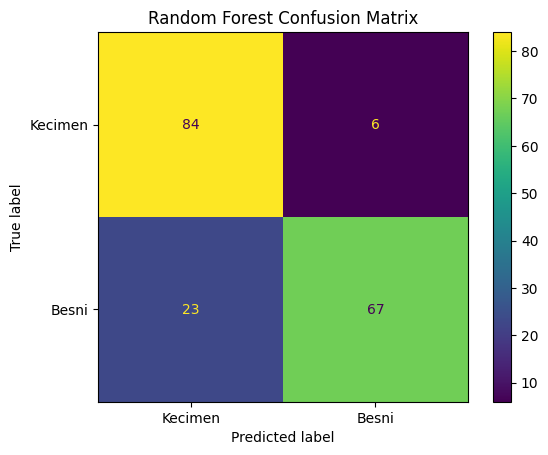

In [78]:
cm_rf = confusion_matrix(
    y_test,
    y_test_pred_rf,
    labels=["Kecimen", "Besni"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Kecimen", "Besni"]
)

disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

#### Random Forest w/ GridSearchCV

In [79]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [2, 4, 6, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", None]
}

rf_grid_model = RandomForestClassifier(
    random_state=42
)

grid_search_rf = GridSearchCV(
    estimator=rf_grid_model,
    param_grid=param_grid_rf,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search_rf.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search_rf.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search_rf.best_score_)

Best Parameters:
{'max_depth': 6, 'max_features': None, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 100}

Best Cross-Validation Accuracy:
0.861111111111111


In [80]:
best_rf = grid_search_rf.best_estimator_

y_train_pred_best_rf = best_rf.predict(X_train)
y_test_pred_best_rf = best_rf.predict(X_test)

print("Tuned Training Accuracy:",
      accuracy_score(y_train, y_train_pred_best_rf))

print("Tuned Testing Accuracy:",
      accuracy_score(y_test, y_test_pred_best_rf))

print("Tuned Testing Precision:",
      precision_score(
          y_test,
          y_test_pred_best_rf,
          pos_label="Besni"
      ))

print("Tuned Testing Recall:",
      recall_score(
          y_test,
          y_test_pred_best_rf,
          pos_label="Besni"
      ))

print("Tuned Testing F1:",
      f1_score(
          y_test,
          y_test_pred_best_rf,
          pos_label="Besni"
      ))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_best_rf
))

Tuned Training Accuracy: 0.8986111111111111
Tuned Testing Accuracy: 0.8777777777777778
Tuned Testing Precision: 0.9473684210526315
Tuned Testing Recall: 0.8
Tuned Testing F1: 0.8674698795180723

Classification Report:
              precision    recall  f1-score   support

       Besni       0.95      0.80      0.87        90
     Kecimen       0.83      0.96      0.89        90

    accuracy                           0.88       180
   macro avg       0.89      0.88      0.88       180
weighted avg       0.89      0.88      0.88       180



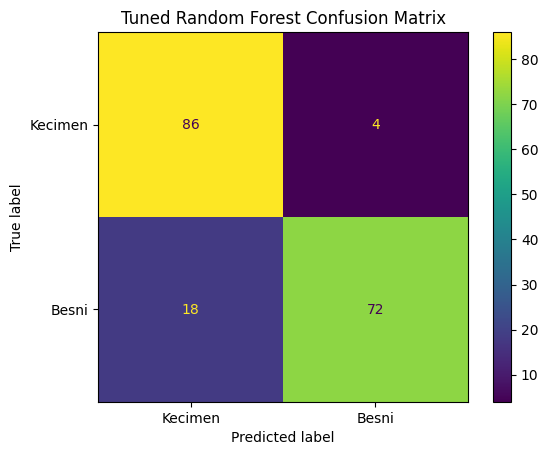

In [81]:
cm_best_rf = confusion_matrix(
    y_test,
    y_test_pred_best_rf,
    labels=["Kecimen", "Besni"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_rf,
    display_labels=["Kecimen", "Besni"]
)

disp.plot()
plt.title("Tuned Random Forest Confusion Matrix")
plt.show()

           Feature  Importance
1  MajorAxisLength    0.855115
0             Area    0.058260
3     Eccentricity    0.054265
2  MinorAxisLength    0.032360


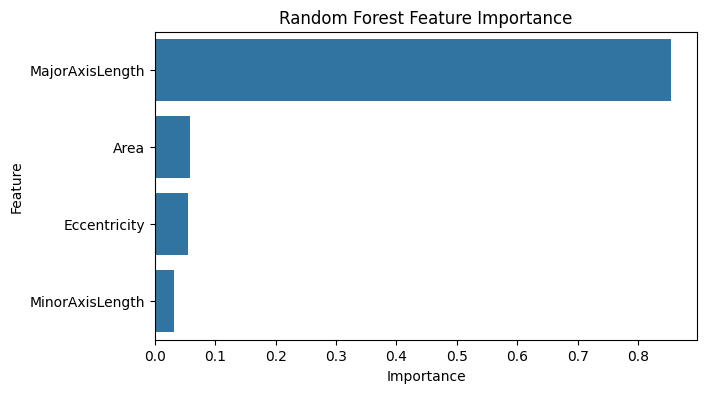

In [82]:
feature_importance_rf = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_rf)

plt.figure(figsize=(7, 4))

sns.barplot(
    data=feature_importance_rf,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### Model Construction - AdaBoost

In [83]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# Weak learner used by AdaBoost
base_tree = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

# Baseline AdaBoost model
ada_model = AdaBoostClassifier(
    estimator=base_tree,
    random_state=42
)

ada_model.fit(X_train, y_train)

# Predictions
y_train_pred_ada = ada_model.predict(X_train)
y_test_pred_ada = ada_model.predict(X_test)

In [84]:
print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred_ada))

print("Testing Accuracy:",
      accuracy_score(y_test, y_test_pred_ada))

print("Testing Precision:",
      precision_score(
          y_test,
          y_test_pred_ada,
          pos_label="Besni"
      ))

print("Testing Recall:",
      recall_score(
          y_test,
          y_test_pred_ada,
          pos_label="Besni"
      ))

print("Testing F1:",
      f1_score(
          y_test,
          y_test_pred_ada,
          pos_label="Besni"
      ))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_ada
    )
)

Training Accuracy: 0.8680555555555556
Testing Accuracy: 0.8777777777777778
Testing Precision: 0.925
Testing Recall: 0.8222222222222222
Testing F1: 0.8705882352941177

Classification Report:
              precision    recall  f1-score   support

       Besni       0.93      0.82      0.87        90
     Kecimen       0.84      0.93      0.88        90

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



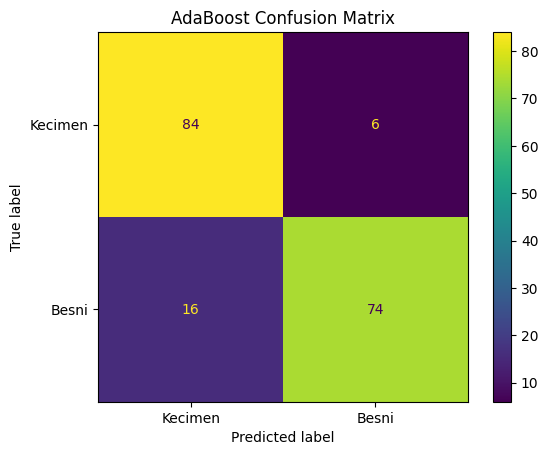

In [85]:
cm_ada = confusion_matrix(
    y_test,
    y_test_pred_ada,
    labels=["Kecimen", "Besni"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ada,
    display_labels=["Kecimen", "Besni"]
)

disp.plot()
plt.title("AdaBoost Confusion Matrix")
plt.show()



#### AdaBoost GridSearchCV


In [86]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

ada_grid_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    random_state=42
)

param_grid_ada = {
    "n_estimators": [25, 50, 100, 200],
    "learning_rate": [0.05, 0.1, 0.5, 1.0],
    "estimator__max_depth": [1, 2, 3]
}

grid_search_ada = GridSearchCV(
    estimator=ada_grid_model,
    param_grid=param_grid_ada,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search_ada.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search_ada.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search_ada.best_score_)

Best Parameters:
{'estimator__max_depth': 1, 'learning_rate': 0.5, 'n_estimators': 200}

Best Cross-Validation Accuracy:
0.8569444444444445


In [87]:
best_ada = grid_search_ada.best_estimator_

y_train_pred_best_ada = best_ada.predict(X_train)
y_test_pred_best_ada = best_ada.predict(X_test)

print("Tuned Training Accuracy:",
      accuracy_score(y_train, y_train_pred_best_ada))

print("Tuned Testing Accuracy:",
      accuracy_score(y_test, y_test_pred_best_ada))

print("Tuned Testing Precision:",
      precision_score(
          y_test,
          y_test_pred_best_ada,
          pos_label="Besni"
      ))

print("Tuned Testing Recall:",
      recall_score(
          y_test,
          y_test_pred_best_ada,
          pos_label="Besni"
      ))

print("Tuned Testing F1:",
      f1_score(
          y_test,
          y_test_pred_best_ada,
          pos_label="Besni"
      ))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_best_ada
))

Tuned Training Accuracy: 0.8666666666666667
Tuned Testing Accuracy: 0.8777777777777778
Tuned Testing Precision: 0.925
Tuned Testing Recall: 0.8222222222222222
Tuned Testing F1: 0.8705882352941177

Classification Report:
              precision    recall  f1-score   support

       Besni       0.93      0.82      0.87        90
     Kecimen       0.84      0.93      0.88        90

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



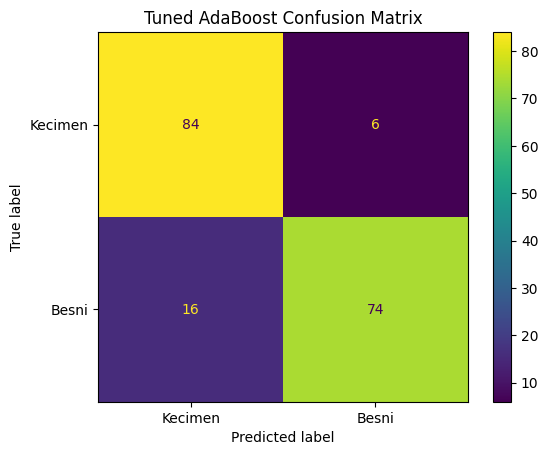

In [88]:
cm_best_ada = confusion_matrix(
    y_test,
    y_test_pred_best_ada,
    labels=["Kecimen", "Besni"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_ada,
    display_labels=["Kecimen", "Besni"]
)

disp.plot()
plt.title("Tuned AdaBoost Confusion Matrix")
plt.show()

### XGBoost

In [89]:
# Encode target for XGBoost
y_train_xgb = y_train.map({
    "Kecimen": 0,
    "Besni": 1
})

y_test_xgb = y_test.map({
    "Kecimen": 0,
    "Besni": 1
})

In [90]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train_xgb)

# Predictions
y_train_pred_xgb = xgb_model.predict(X_train)
y_test_pred_xgb = xgb_model.predict(X_test)

In [91]:
print("Training Accuracy:",
      accuracy_score(y_train_xgb, y_train_pred_xgb))

print("Testing Accuracy:",
      accuracy_score(y_test_xgb, y_test_pred_xgb))

print("Testing Precision:",
      precision_score(y_test_xgb, y_test_pred_xgb))

print("Testing Recall:",
      recall_score(y_test_xgb, y_test_pred_xgb))

print("Testing F1:",
      f1_score(y_test_xgb, y_test_pred_xgb))

print("\nClassification Report:")
print(
    classification_report(
        y_test_xgb,
        y_test_pred_xgb,
        target_names=["Kecimen", "Besni"]
    )
)

Training Accuracy: 0.9972222222222222
Testing Accuracy: 0.8222222222222222
Testing Precision: 0.881578947368421
Testing Recall: 0.7444444444444445
Testing F1: 0.8072289156626506

Classification Report:
              precision    recall  f1-score   support

     Kecimen       0.78      0.90      0.84        90
       Besni       0.88      0.74      0.81        90

    accuracy                           0.82       180
   macro avg       0.83      0.82      0.82       180
weighted avg       0.83      0.82      0.82       180



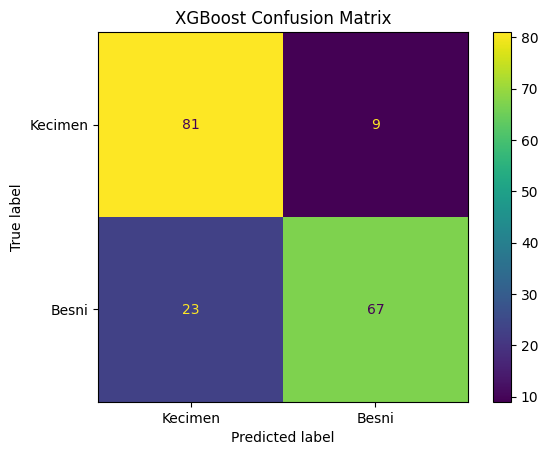

In [92]:
cm_xgb = confusion_matrix(
    y_test_xgb,
    y_test_pred_xgb,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Kecimen", "Besni"]
)

disp.plot()
plt.title("XGBoost Confusion Matrix")
plt.show()

#### XGBoost w/ GridSearchCV

In [93]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

xgb_grid_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

param_grid_xgb = {
    "n_estimators": [50, 100, 200],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.05, 0.1, 0.2],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

grid_search_xgb = GridSearchCV(
    estimator=xgb_grid_model,
    param_grid=param_grid_xgb,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search_xgb.fit(X_train, y_train_xgb)

print("Best Parameters:")
print(grid_search_xgb.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search_xgb.best_score_)

Best Parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100, 'subsample': 1.0}

Best Cross-Validation Accuracy:
0.8638888888888889


In [94]:
best_xgb = grid_search_xgb.best_estimator_

y_train_pred_best_xgb = best_xgb.predict(X_train)
y_test_pred_best_xgb = best_xgb.predict(X_test)

print("Tuned Training Accuracy:",
      accuracy_score(y_train_xgb, y_train_pred_best_xgb))

print("Tuned Testing Accuracy:",
      accuracy_score(y_test_xgb, y_test_pred_best_xgb))

print("Tuned Testing Precision:",
      precision_score(y_test_xgb, y_test_pred_best_xgb))

print("Tuned Testing Recall:",
      recall_score(y_test_xgb, y_test_pred_best_xgb))

print("Tuned Testing F1:",
      f1_score(y_test_xgb, y_test_pred_best_xgb))

print("\nClassification Report:")
print(
    classification_report(
        y_test_xgb,
        y_test_pred_best_xgb,
        target_names=["Kecimen", "Besni"]
    )
)

Tuned Training Accuracy: 0.9083333333333333
Tuned Testing Accuracy: 0.85
Tuned Testing Precision: 0.9315068493150684
Tuned Testing Recall: 0.7555555555555555
Tuned Testing F1: 0.8343558282208589

Classification Report:
              precision    recall  f1-score   support

     Kecimen       0.79      0.94      0.86        90
       Besni       0.93      0.76      0.83        90

    accuracy                           0.85       180
   macro avg       0.86      0.85      0.85       180
weighted avg       0.86      0.85      0.85       180



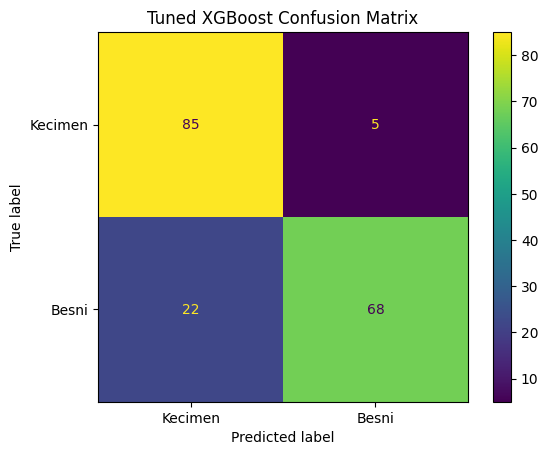

In [95]:
cm_best_xgb = confusion_matrix(
    y_test_xgb,
    y_test_pred_best_xgb,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best_xgb,
    display_labels=["Kecimen", "Besni"]
)

disp.plot()
plt.title("Tuned XGBoost Confusion Matrix")
plt.show()

## All Model Comparisons

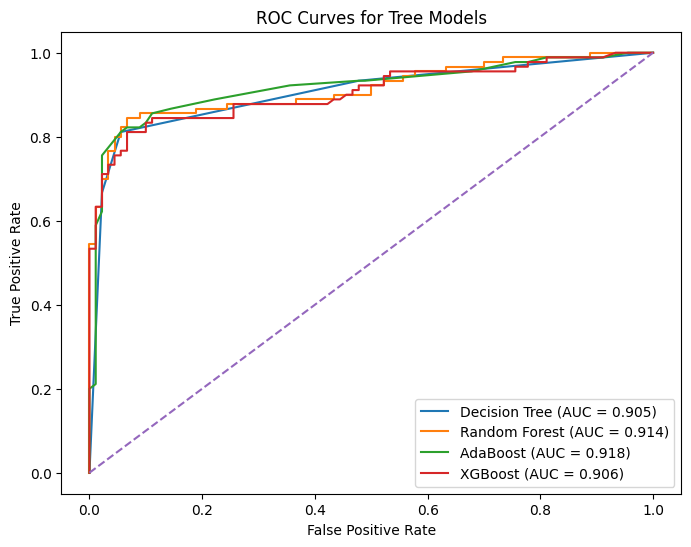

In [96]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get probability column corresponding to Besni
dt_besni_index = list(best_dt.classes_).index("Besni")
rf_besni_index = list(best_rf.classes_).index("Besni")
ada_besni_index = list(best_ada.classes_).index("Besni")

dt_prob = best_dt.predict_proba(X_test)[:, dt_besni_index]
rf_prob = best_rf.predict_proba(X_test)[:, rf_besni_index]
ada_prob = best_ada.predict_proba(X_test)[:, ada_besni_index]

# For XGBoost, Besni was encoded as 1
xgb_prob = best_xgb.predict_proba(X_test)[:, 1]

# Binary version of actual test labels
y_test_binary = y_test.map({
    "Kecimen": 0,
    "Besni": 1
})

models_prob = {
    "Decision Tree": dt_prob,
    "Random Forest": rf_prob,
    "AdaBoost": ada_prob,
    "XGBoost": xgb_prob
}

plt.figure(figsize=(8, 6))

for name, probabilities in models_prob.items():
    fpr, tpr, thresholds = roc_curve(
        y_test_binary,
        probabilities
    )

    auc = roc_auc_score(
        y_test_binary,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Tree Models")
plt.legend()
plt.show()

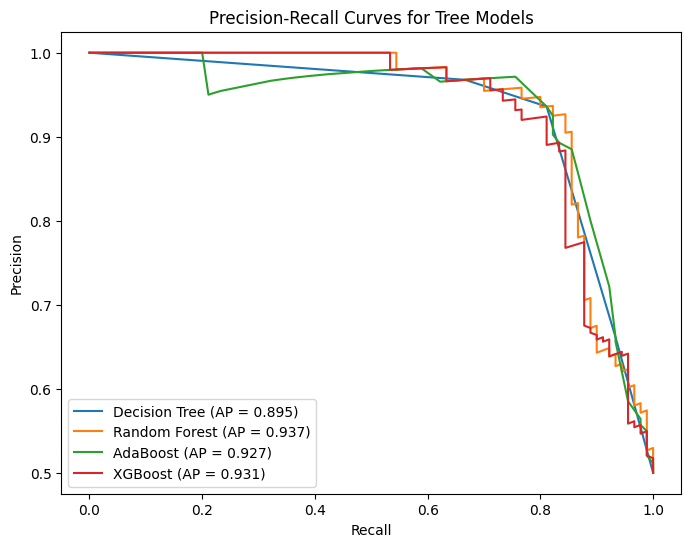

In [97]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

for name, probabilities in models_prob.items():
    precision, recall, thresholds = precision_recall_curve(
        y_test_binary,
        probabilities
    )

    ap = average_precision_score(
        y_test_binary,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves for Tree Models")
plt.legend()
plt.show()

In [98]:
final_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "XGBoost"
    ],
    "Test Accuracy": [
        0.877,
        0.877,
        0.877,
        0.850
    ],
    "Precision": [
        0.936,
        0.947,
        0.925,
        0.931
    ],
    "Recall": [
        0.811,
        0.800,
        0.822,
        0.756
    ],
    "F1": [
        0.870,
        0.867,
        0.870,
        0.834
    ],
    "ROC AUC": [
        0.905,
        0.914,
        0.918,
        0.906
    ],
    "Average Precision": [
        0.895,
        0.937,
        0.927,
        0.931
    ]
})

final_results

,Model,Test Accuracy,Precision,Recall,F1,ROC AUC,Average Precision
0,Decision Tree,0.877,0.936,0.811,0.870,0.905,0.895
1,Random Forest,0.877,0.947,0.800,0.867,0.914,0.937
2,AdaBoost,0.877,0.925,0.822,0.870,0.918,0.927
3,XGBoost,0.850,0.931,0.756,0.834,0.906,0.931
